# 06 — Unified Model Evaluation (Validation Only)

Compare the **Dense baseline**, **CNN from scratch**, and **ResNet50 transfer learning** using the **same 1,051-image validation split**. This notebook **does not load the test set**.

**Outputs:** ROC curves, confusion matrices, probability calibration plots, model comparison CSV, and per-image prediction CSV.

> **Research limitation:** Prior split reports indicated possible patient-ID overlap involving the held-out test split. Resolve that before independent test reporting. Also, thresholds chosen on validation data can make validation metrics optimistic. These images and labels are for a course experiment, **not clinical diagnosis**.

## 1. Imports, project paths, and reproducibility

In [1]:
from pathlib import Path
import gc
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
)
from sklearn.calibration import calibration_curve

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "processed_224_pad_gray"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 8  # Appropriate starting point for an M1 Mac running on CPU
TARGET_SPECIFICITY = 0.95
SEED = 42
keras.utils.set_random_seed(SEED)

print("Python:", sys.version.split()[0], "TensorFlow:", tf.__version__)
print("Working directory:", Path.cwd())
print("Project:", PROJECT_DIR)
print("GPU devices:", tf.config.list_physical_devices('GPU'))
assert (DATA_DIR / 'validation.npz').exists(), f"Missing: {DATA_DIR / 'validation.npz'}"

Python: 3.13.7 TensorFlow: 2.21.0
Working directory: /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/notebooks
Project: /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification
GPU devices: []


## 2. Load validation images only (uint8, memory efficient)

In [2]:
with np.load(DATA_DIR / "validation.npz") as archive:
    X_val = archive["images"]  # Expected shape (N, 224, 224), uint8
    y_val = archive["labels"].astype(np.int32)

assert X_val.ndim == 3 and X_val.shape[1:] == (224, 224)
assert len(X_val) == len(y_val)
assert set(np.unique(y_val)) == {0, 1}, "Both NORMAL=0 and PNEUMONIA=1 required"
assert X_val.dtype == np.uint8, "Expected uint8 original pixels (0..255); inspect preprocessing if different"

print("Images:", X_val.shape, X_val.dtype)
print("Labels (0=NORMAL, 1=PNEUMONIA):", dict(zip(*np.unique(y_val, return_counts=True))))

Images: (1051, 224, 224) uint8
Labels (0=NORMAL, 1=PNEUMONIA): {np.int32(0): np.int64(268), np.int32(1): np.int64(783)}


## 3. Input preparation for each saved model

- **Dense:** float32 image values in [0,1], shape `(B,224,224)`.
- **CNN:** the same values with a singleton channel, shape `(B,224,224,1)`.
- **ResNet50:** repeat grayscale to three channels, then apply `keras.applications.resnet50.preprocess_input` to **0–255** pixels. Do **not** divide ResNet inputs by 255.

Inputs are converted **one batch at a time**, limiting RAM use.

In [3]:
def make_validation_ds(kind):
    ds = tf.data.Dataset.from_tensor_slices(X_val).batch(BATCH_SIZE)

    def process(batch):
        batch = tf.cast(batch, tf.float32)
        if kind == "dense":
            return batch / 255.0
        if kind == "cnn":
            return tf.expand_dims(batch / 255.0, -1)
        if kind == "resnet":
            batch = tf.expand_dims(batch, -1)
            batch = tf.repeat(batch, repeats=3, axis=-1)
            return keras.applications.resnet50.preprocess_input(batch)
        raise ValueError(f"Unknown model kind: {kind}")

    return ds.map(process, num_parallel_calls=1).prefetch(1)

for kind in ["dense", "cnn", "resnet"]:
    one = next(iter(make_validation_ds(kind).take(1)))
    print(kind, one.shape, one.dtype)

dense (8, 224, 224) <dtype: 'float32'>
cnn (8, 224, 224, 1) <dtype: 'float32'>
resnet (8, 224, 224, 3) <dtype: 'float32'>


## 4. Predict using each saved checkpoint

In [4]:
models_to_run = {
    "Dense baseline": (MODEL_DIR / "dense_baseline.keras", "dense"),
    "CNN from scratch": (MODEL_DIR / "cnn_from_scratch.keras", "cnn"),
    "ResNet50 transfer": (MODEL_DIR / "resnet50_transfer.keras", "resnet"),
}

for name, (path, kind) in models_to_run.items():
    assert path.exists(), f"Missing model for {name}: {path}. Run its training notebook first."

prediction_probs = {}
for name, (path, kind) in models_to_run.items():
    print(f"\nLoading {name}: {path.name}")
    model = keras.models.load_model(path, compile=False)
    probs = model.predict(make_validation_ds(kind), verbose=1).reshape(-1)
    assert len(probs) == len(y_val), f"Unexpected prediction count for {name}"
    assert np.isfinite(probs).all(), f"Nonfinite probabilities from {name}"
    assert np.logical_and(probs >= 0, probs <= 1).all(), f"Expected sigmoid probabilities for {name}"
    prediction_probs[name] = probs.astype(np.float64)
    print("Probability range:", round(float(probs.min()), 4), "to", round(float(probs.max()), 4))
    del model
    keras.backend.clear_session()
    gc.collect()

print("\nPredictions complete for:", list(prediction_probs))


Loading Dense baseline: dense_baseline.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Probability range: 0.0388 to 1.0

Loading CNN from scratch: cnn_from_scratch.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step
Probability range: 0.0233 to 0.9993

Loading ResNet50 transfer: resnet50_transfer.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 225ms/step
Probability range: 0.0 to 1.0

Predictions complete for: ['Dense baseline', 'CNN from scratch', 'ResNet50 transfer']


## 5. Select comparable classification thresholds

For each model, select the **highest validation sensitivity** among ROC points meeting **≥95% validation specificity**. For ties, choose the **highest (most conservative) finite threshold**. We also report 0.5 threshold metrics separately.

**Note:** Thresholds are tuned using this same validation set, so operating-point performance is descriptive and can be optimistic. Use these selected thresholds *unchanged* on a future truly independent test set.

In [5]:
def choose_threshold(y_true, probs, target_specificity=0.95):
    fpr, tpr, thresholds = roc_curve(y_true, probs)
    specificity = 1 - fpr
    eligible = np.flatnonzero((specificity >= target_specificity) & np.isfinite(thresholds))
    if len(eligible) == 0:
        # Only possible for unusual numerical behavior; >max probability predicts all negative.
        return float(np.nextafter(np.max(probs), np.inf))
    best_sens = np.max(tpr[eligible])
    best = eligible[np.isclose(tpr[eligible], best_sens)]
    return float(np.max(thresholds[best]))


def calculate_metrics(y_true, probs, threshold):
    predicted = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "roc_auc": roc_auc_score(y_true, probs),
        "accuracy": accuracy_score(y_true, predicted),
        "sensitivity": recall_score(y_true, predicted, pos_label=1, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "precision": precision_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "brier_score": brier_score_loss(y_true, probs),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

selected_thresholds = {}
rows = []
for name, probs in prediction_probs.items():
    t = choose_threshold(y_val, probs, TARGET_SPECIFICITY)
    selected_thresholds[name] = t
    for policy, threshold in [("0.50 default", 0.5), ("validation >=95% specificity", t)]:
        rows.append({"model": name, "threshold_policy": policy,
                     **calculate_metrics(y_val, probs, threshold)})

metrics_df = pd.DataFrame(rows)
display(metrics_df.round(4))
metrics_path = RESULTS_DIR / "model_comparison_validation.csv"
metrics_df.to_csv(metrics_path, index=False)
print("Saved:", metrics_path)

,model,threshold_policy,threshold,roc_auc,accuracy,sensitivity,specificity,precision,f1,brier_score,tn,fp,fn,tp
0,Dense baseline,0.50 default,0.5000,0.9830,0.9286,0.9885,0.7537,0.9214,0.9538,0.0550,202,66,9,774
1,Dense baseline,validation >=95% specificity,0.8350,0.9830,0.9277,0.9183,0.9552,0.9836,0.9498,0.0550,256,12,64,719
2,CNN from scratch,0.50 default,0.5000,0.9625,0.9058,0.9195,0.8657,0.9524,0.9357,0.0687,232,36,63,720
3,CNN from scratch,validation >=95% specificity,0.7426,0.9625,0.8820,0.8582,0.9515,0.9810,0.9155,0.0687,255,13,111,672
4,ResNet50 transfer,0.50 default,0.5000,0.9959,0.9762,0.9770,0.9739,0.9909,0.9839,0.0212,261,7,18,765
5,ResNet50 transfer,validation >=95% specificity,0.3234,0.9959,0.9781,0.9860,0.9552,0.9847,0.9853,0.0212,256,12,11,772


Saved: /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/results/model_comparison_validation.csv


## 6. Compare ROC curves (threshold-independent)

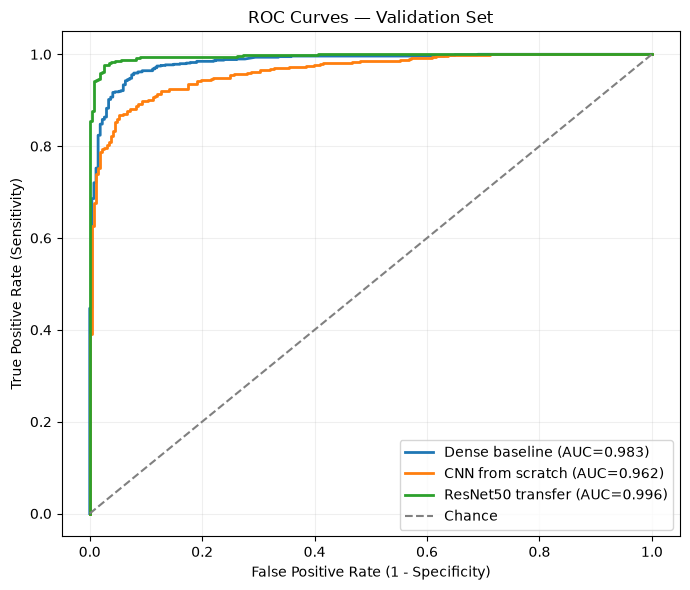

In [6]:
plt.figure(figsize=(7, 6))
for name, probs in prediction_probs.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc = roc_auc_score(y_val, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curves — Validation Set")
plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_roc_curves.png", dpi=160)
plt.show()

## 7. Confusion matrices at selected operating points

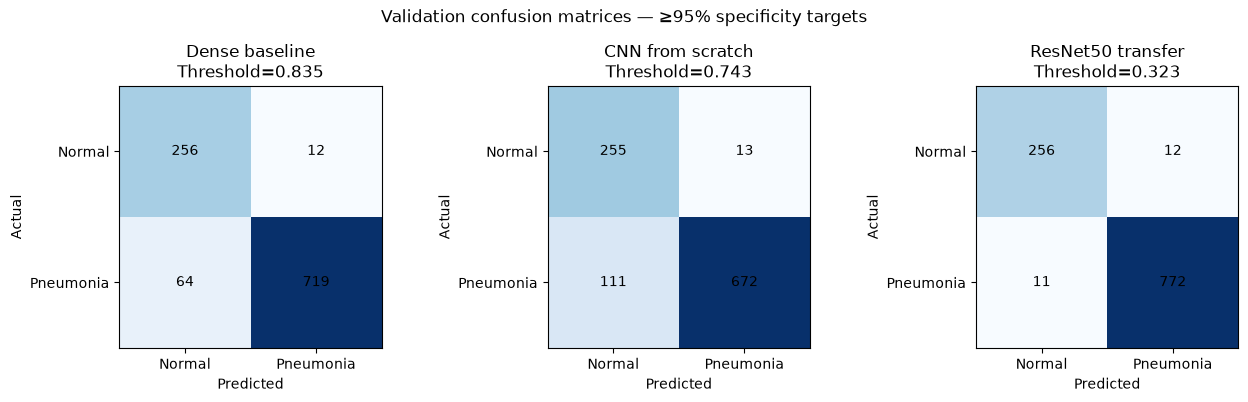

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, probs) in zip(axes, prediction_probs.items()):
    t = selected_thresholds[name]
    cm = confusion_matrix(y_val, probs >= t, labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), va='center', ha='center')
    ax.set_xticks([0, 1], ['Normal', 'Pneumonia'])
    ax.set_yticks([0, 1], ['Normal', 'Pneumonia'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{name}\nThreshold={t:.3f}')
plt.suptitle('Validation confusion matrices — ≥95% specificity targets')
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_confusion_matrices.png", dpi=160)
plt.show()

## 8. Probability calibration

A model can discriminate well (high AUC) but output poorly calibrated probabilities. The **Brier score** measures squared error between probabilities and labels (lower is better). Calibration diagrams use 10 equal-width bins; bins with zero samples are omitted.

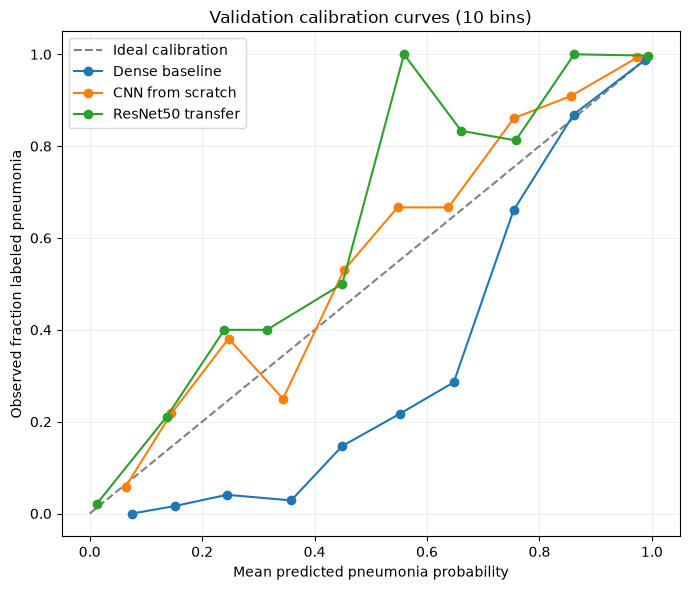

Brier scores (lower = better):
Dense baseline: 0.0550
CNN from scratch: 0.0687
ResNet50 transfer: 0.0212


In [8]:
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ideal calibration')
for name, probs in prediction_probs.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_val, probs, n_bins=10, strategy='uniform'
    )
    plt.plot(mean_predicted, fraction_positive, marker='o', label=name)
plt.xlabel('Mean predicted pneumonia probability')
plt.ylabel('Observed fraction labeled pneumonia')
plt.title('Validation calibration curves (10 bins)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'validation_calibration_curves.png', dpi=160)
plt.show()
print('Brier scores (lower = better):')
for name, probs in prediction_probs.items():
    print(f'{name}: {brier_score_loss(y_val, probs):.4f}')

## 9. Save prediction scores and selected thresholds

In [9]:
predictions_df = pd.DataFrame({
    'validation_row_index': np.arange(len(y_val)),
    'true_label': y_val,
})
for name, probs in prediction_probs.items():
    safe_name = {'Dense baseline': 'dense', 'CNN from scratch': 'cnn',
                 'ResNet50 transfer': 'resnet50'}[name]
    predictions_df[f'{safe_name}_prob_pneumonia'] = probs
    predictions_df[f'{safe_name}_pred_at_selected_threshold'] = (
        probs >= selected_thresholds[name]
    ).astype(int)

predictions_df.to_csv(RESULTS_DIR / 'validation_all_model_predictions.csv', index=False)
pd.DataFrame([{'model': name, 'threshold': t, 'threshold_selected_on': 'validation',
               'target_specificity': TARGET_SPECIFICITY}
              for name, t in selected_thresholds.items()]).to_csv(
    RESULTS_DIR / 'selected_thresholds_validation.csv', index=False
)
print('Predictions and thresholds saved to results/')
display(predictions_df.head())

Predictions and thresholds saved to results/


,validation_row_index,true_label,dense_prob_pneumonia,dense_pred_at_selected_threshold,cnn_prob_pneumonia,cnn_pred_at_selected_threshold,resnet50_prob_pneumonia,resnet50_pred_at_selected_threshold
0,0,0,0.303025,0,0.344203,0,0.000341,0
1,1,0,0.144211,0,0.166505,0,0.000270,0
2,2,0,0.081198,0,0.041873,0,0.003530,0
3,3,0,0.237806,0,0.341818,0,0.004140,0
4,4,0,0.858928,1,0.888441,1,0.112629,0


## 10. Summary and interpretation

In [10]:
selected = metrics_df[metrics_df['threshold_policy'] == 'validation >=95% specificity']
print('MODEL COMPARISON — VALIDATION ONLY')
display(selected[['model', 'roc_auc', 'sensitivity', 'specificity',
                  'accuracy', 'f1', 'brier_score', 'threshold']].round(4))

print('\nGenerated files:')
for path in sorted(RESULTS_DIR.glob('validation_*')):
    if path.is_file(): print('•', path.relative_to(PROJECT_DIR))
for name in ['model_comparison_validation.csv', 'selected_thresholds_validation.csv']:
    print('•', (RESULTS_DIR / name).relative_to(PROJECT_DIR))
print('\nNo test images were loaded or evaluated.')

MODEL COMPARISON — VALIDATION ONLY


,model,roc_auc,sensitivity,specificity,accuracy,f1,brier_score,threshold
1,Dense baseline,0.9830,0.9183,0.9552,0.9277,0.9498,0.0550,0.8350
3,CNN from scratch,0.9625,0.8582,0.9515,0.8820,0.9155,0.0687,0.7426
5,ResNet50 transfer,0.9959,0.9860,0.9552,0.9781,0.9853,0.0212,0.3234



Generated files:
• results/validation_all_model_predictions.csv
• results/validation_calibration_curves.png
• results/validation_confusion_matrices.png
• results/validation_roc_curves.png
• results/model_comparison_validation.csv
• results/selected_thresholds_validation.csv

No test images were loaded or evaluated.


## Next steps

1. Review the ROC curves, confusion matrices, calibration, and table above.
2. Investigate and document potential patient-ID overlap in `splits/reports/leakage_report.csv` before test claims.
3. Once the evaluation protocol is fixed, evaluate on an **independent** held-out test set **once**, using these saved thresholds rather than choosing new ones from test results.
4. Next research experiments: cross-dataset generalization and Grad-CAM.

**Interpretation caution:** Comparing ROC-AUC is more robust than simply comparing accuracy on an imbalanced dataset. Sensitivity at a preselected specificity is useful, but the validation-selected threshold is not an unbiased estimate of real-world clinical performance.